In [1]:
## Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
import math
import ipynbname
import os

<div><h3>Contents</h3>
<ol>
    <li>Functions</li>
    <li>Logistic Map</li>
    <li>Bifurcation of Logistic Map</li>
    <li> Bifurcation of Circle Map</li>
</ol>
</div>



<div><h2 style = "text-align:center">Functions</h2></div>


In [10]:
## Functions (to define coupled logistic and cirle maps)

def logistic(x0, r=4):
    x0 = np.asarray(x0)
    y = r*x0*(1-x0)
    return y
    
def circle(x0, r, K=6.9115):
    x0 = np.asarray(x0)
    y= x0+r-(K/(2*math.pi))*math.sin(2*math.pi*x0)
    y = y%1
    return y


<div><h2 style = "text-align:center">Logistic Map</h2></div>


In [3]:
x0 = random.random()
r= 4
k = 10**4# The length of trajectory.
trajectory_log = np.zeros((k,1))
x= x0
for i in range(0,k):
    trajectory_log[i] = x
    x = logistic(x, r)

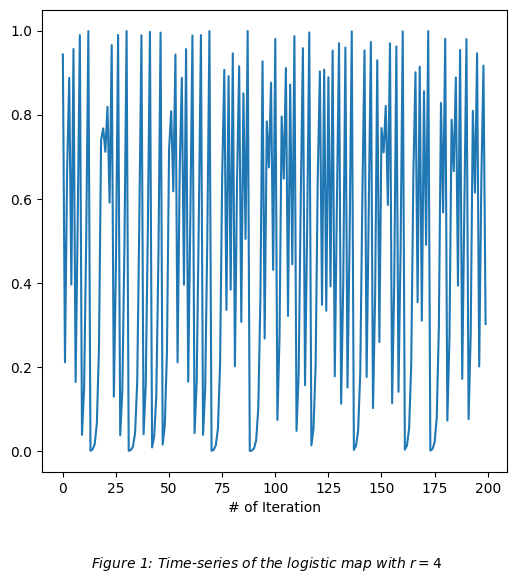

In [4]:
plt.figure(figsize= (6,6))
plt.plot(trajectory_log[9800:])
plt.figtext(
    0.5, -0.05, 
    "Figure 1: Time-series of the logistic map with $r=4$", 
    wrap=True, horizontalalignment="center", fontsize=10, style="italic"
)
plt.xlabel('# of Iteration')
plt.show()

<h3 style = "text-align:center">BIFURCATION OF LOGISTIC MAP</h3>

<div>This behaviour of period doubling can be depicted by the bifurcation diagram, shown in Figure 2. This diagram shows the intricate long-term behaviour of the logistic map. In particular, the logistic map exhibits a diverse range of behaviours. For instance, orbits rapidly transform into chaos around $r= 3.6$ after doubling a period. An emergence of period $3$ behaviour is observed around $r= 3.84$, followed by a rapid escalation of irregularity. 
</div>

In [5]:
x0 = random.random()
r_list= np.linspace(1,4,10**3)
k=10**4
traj_logs = np.zeros((k,len(r_list)))
for r_rank, r in enumerate(r_list):
    x = x0
    for i in range(0,k):
        traj_logs[i,r_rank] = x
        x = logistic(x, r)

In [6]:
notebook_name = ipynbname.name()

# 2. Create the directory if it does not already exist
output_dir = f"Output_{notebook_name}"
os.makedirs(output_dir, exist_ok=True)
print(output_dir)

Output_3.DiscreteModels_Logistic_Circle


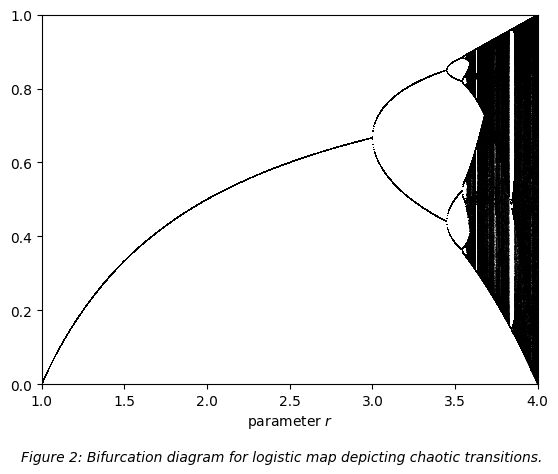

In [7]:
removable_len = 7*(10**3)
rest = k - removable_len
plt.figure()
for i, r in enumerate(r_list):
    r_array = np.full((rest,1), r)
    plt.scatter(
    r_array, 
    traj_logs[removable_len:, i], 
    color="black", 
    marker=".", 
    s=1,                  # Marker area in points^2
    edgecolors="none")     # Prevents white or hollow edge artifacts
plt.xlim([1,4]); plt.ylim([0,1])
plt.xlabel("parameter $r$")
plt.figtext(
    0.5, -0.05, 
    "Figure 2: Bifurcation diagram for logistic map depicting chaotic transitions.", 
    wrap=True, horizontalalignment="center", fontsize=10, style="italic")
plt.savefig(f"{output_dir}/bifurcation_diagram_logistic.tiff", dpi=300, bbox_inches="tight")    
plt.show()

<h3 style = "text-align:center">BIFURCATION OF CIRCLE MAP</h3>

<div> Similarly, we plot the bifurcation diagram for the circle map in Figure 3 is given by,
\[ f(x,r) = x+ r− \frac{K}{2\pi} \sin(2\pi xn) \mod 1
\]
where $r$ is a parameter in $[0,1]$, $x$ the input variable in $[0,1]$ and $K = 6.9115$. Figure 3 reveals various dynamics similar to that observed in the logistic map. For the system to be chaotic, we will choose r= 0.35 in the upcoming computations.</div>

In [8]:
x0 = random.random()
r_list= np.linspace(0,1,10**3)
k=10**4 # time-series length
traj_circ = np.zeros((k,len(r_list)))
for r_rank, r in enumerate(r_list):
    x = x0
    for i in range(0,k):
        traj_circ[i,r_rank] = x
        x = circle(x, r)

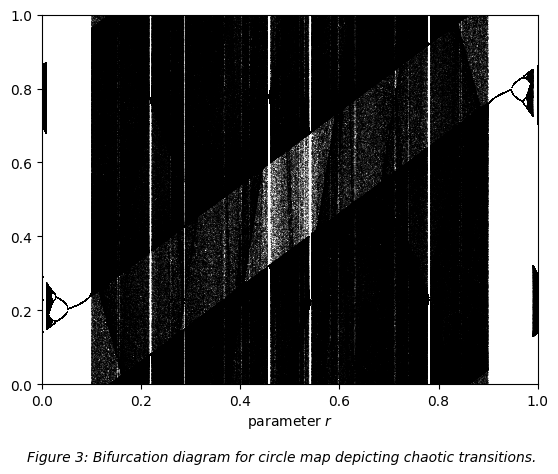

In [9]:
removable_len = 7*(10**3)
rest = k - removable_len
plt.figure()
for i, r in enumerate(r_list):
    r_array = np.full((rest,1), r)
    plt.scatter(
    r_array, 
    traj_circ[removable_len:, i], 
    color="black", 
    marker=".", 
    s=1,                  # Marker area in points^2
    edgecolors="none")     # Prevents white or hollow edge artifacts
plt.xlim([0,1]); plt.ylim([0,1])
plt.xlabel("parameter $r$")
plt.figtext(
    0.5, -0.05, 
    "Figure 3: Bifurcation diagram for circle map depicting chaotic transitions.", 
    wrap=True, horizontalalignment="center", fontsize=10, style="italic")
plt.savefig(f"{output_dir}/bifurcation_diagram_circle.tiff", dpi=300, bbox_inches="tight")    
plt.show()